## Problema - Organización y búsqueda de productos en una tienda





In [ ]:

nombre_estudiante = "Andres Felipe Marin Velez", "Maria Fernanda Garzon Pirachican", "Ana Lucia Avendaño Mendoza", "Thomas Mauricio Rodriguez"
carnet = 1000112123


## 1) Descripción del problema **[1 pts]**

Representar una red social mediante un grafo no dirigido, implementando BFS y DFS, calcular sus grados de separacion, encontrar rutas minimas y agregar usuarios

## 2) Requerimientos **[2 pts]**

## Requerimentos funcionales:
1.  crear una lista de adyacencia y un grafo con los usuarios y sus conexiones
2.  mostrar el grafo y lista de adyacencia
3.  realizar un recorrido BFS utilizando una cola desde un usuario x inicial
4.  mostrar el orden en que se visitó a los usuarios y separación entre estos
5.  realizar un recorrido DFS con recursividad o una pila
6.  a través del BFS hallar el recorrido con menos saltos entre el usuario inicial y el final
7.  mostrar si no hay relación entre dos usuarios
## Requerimientos no funcionales:
1. el programa debe ser fácil de usar y darle diversos mensajes al usuario
2. toda la información de la red debe guardarse en una lista de adyacencia
3. los algoritmos BFS y DFS deben operar manualmente
4. la red debe ser consistente y no ser unidireccional
5. el programa debe evitar errores en los nombres de los usuarios
6. el programa debe señalar cuando ya existe una conexión entre ambos usuarios

## 3) Historias de usuario **[2 pts]**

Visualizar la red social
Como usuario, quiero ver cada persona con sus amigos directos para conocer cómo está organizada la red social.
Criterio de aceptación: el programa muestra todos los usuarios y sus conexiones mediante una lista de adyacencia.

Explorar la red mediante BFS
Como usuario, quiero recorrer la red desde una persona inicial para conocer el orden de visita y los grados de separación de los demás usuarios.
Criterio de aceptación: el programa utiliza una cola, inicia en el usuario seleccionado y muestra la distancia de cada usuario alcanzable.

Explorar la red mediante DFS
Como usuario, quiero recorrer la red profundizando por una rama para conocer las conexiones siguiendo ese orden de exploración.
Criterio de aceptación: el programa implementa DFS mediante recursividad y evita visitar dos veces el mismo usuario.

Seleccionar el usuario inicial
Como usuario, quiero elegir desde qué persona iniciar los recorridos para analizar diferentes partes de la red.
Criterio de aceptación: si el nombre no existe, se muestra un mensaje de error.

Encontrar la ruta más corta
Como usuario, quiero ingresar dos personas para encontrar una ruta con la menor cantidad de conexiones entre ellas.
Criterio de aceptación: el programa muestra la ruta y el número de conexiones, o informa que no existe una ruta.



## 4) Diagramas de flujo **[5 pts]**

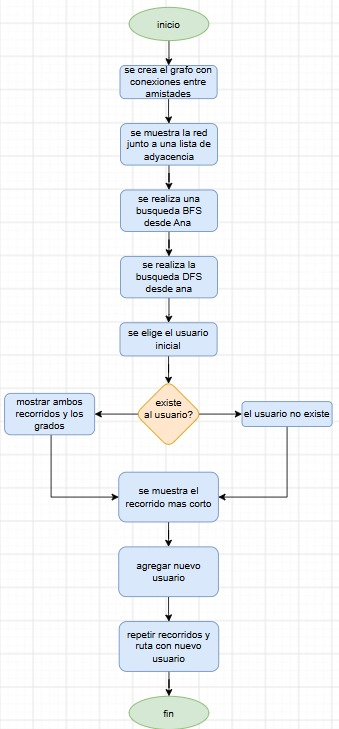               

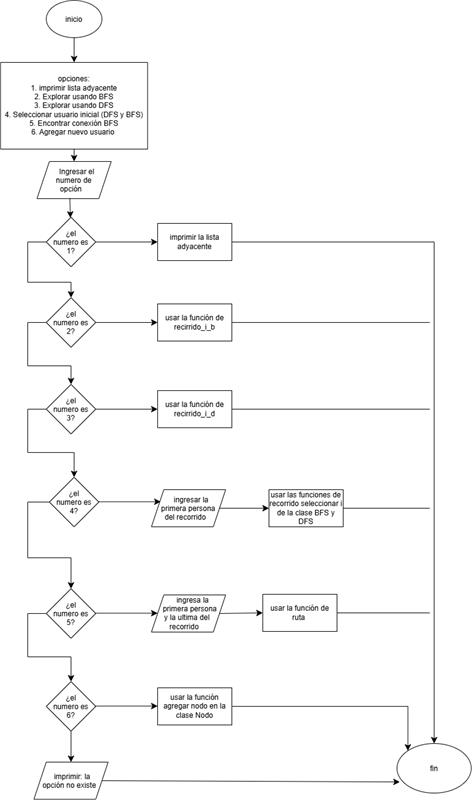



### 5) Análisis de complejidad **[15 pts]**
Incluye:

JUSTIFICACIÓN: Utilizamos listas de adyacencia para representar la red social. BFS recorre los usuarios mediante una cola y DFS utiliza recursividad. Como usamos listas para guardar los visitados y pop(0) para manejar la cola, algunas operaciones requieren más tiempo cuando aumenta la cantidad de usuarios.

FUNCIÓN T(n):
n = Número de usuarios.
T(n) = an³ + bn² + cn + d
Complejidad del peor caso: O(n³).

MEJOR CASO: T(n) = c → O(1).
Ocurre cuando el usuario inicial no tiene conexiones o cuando buscamos una ruta hacia el mismo usuario. La grafica es constante.
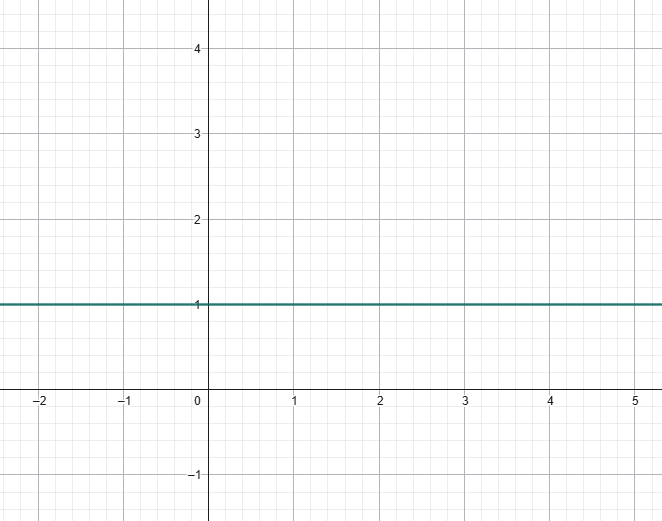


PEOR CASO: O(n³).
Ocurre cuando tenemos muchos usuarios conectados entre sí y debemos revisar todas sus conexiones. Como utilizamos listas para comprobar los visitados, el tiempo puede crecer de forma cúbica. La gráfica es una curva creciente.

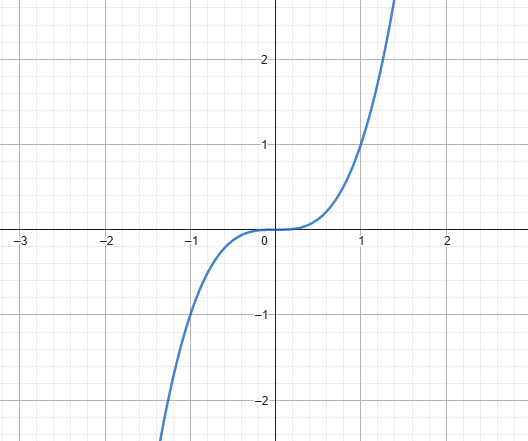

CONCLUSIÓN: En nuestro código, BFS y DFS pueden alcanzar una complejidad temporal de O(n³) en el peor caso cuando la red tiene muchas conexiones. En el mejor caso, el recorrido es O(1) si el usuario inicial está aislado.





## 6) Código funcional **[15 pts]**
Incluye tu implementación completa.

No pegues código incompleto; debe ser ejecutable.


In [ ]:

grafos_personas = {
    "Ana": ["Carlos", "Laura"],
    "Carlos": ["Ana", "Mateo", "Sofia"],
    "Mateo": ["Carlos"],
    "Laura": ["Ana", "Daniel"],
    "Sofia": ["Carlos","Valentina"],
    "Daniel": ["Laura", "Valentina"],
    "Valentina": ["Daniel", "Sofia"]
}
 
class BFS:
    def __init__(self):
        self.grafo = grafos_personas
        self.list_grafo = list(grafos_personas)
 
    def recorrido_i_b (self):
        visitados = []
        cola_i = [self.list_grafo[0]]
 
        visitados.append(self.list_grafo[0])
 
        while cola_i:
            est_a = cola_i.pop(0)
 
            for v in self.grafo[est_a]:
                if v not in visitados:
                    visitados.append(v)
                    cola_i.append(v)
        print(visitados)
   
    def ele_inicio_b(self, inicio):
        if inicio not in self.grafo:
            print ("Esta persona no existe.")
            return None
 
        visitados = []
        cola_i = [inicio]
       
        visitados.append(inicio)
 
        while cola_i:
            est_a = cola_i.pop(0)
 
            for v in self.grafo[est_a]:
                if v not in visitados:
                    visitados.append(v)
                    cola_i.append(v)
        print(visitados)
 
    def ruta(self, inicio, fin):
        if inicio not in self.grafo or fin not in self.grafo:
            print ("Esta persona no existe.")
            return None
 
        visitados = {inicio}
        cola_i = [[inicio]]
 
        while cola_i:
            est_a = cola_i.pop(0)
            nodo_a = est_a[-1]
 
            if nodo_a == fin:
                print(est_a)
                return est_a
 
            for v in self.grafo[nodo_a]:
                if v not in visitados:
                    visitados.add(v)
 
                    new_ruta = list(est_a)
                    new_ruta.append(v)
                    cola_i.append(new_ruta)
        print(visitados)
 
class DFS:
    def __init__(self):
        self.grafo = grafos_personas
        self.list_grafo = list(grafos_personas)
 
    def ele_inicio_d(self, inicio):
            vicitados = []
   
            self.dfs_recursivo(inicio, vicitados)
   
            print(vicitados)
 
    def recorrido_i_d(self):
        vicitados = []
 
        self.dfs_recursivo(self.list_grafo[0], vicitados)
 
        print(vicitados)
 
    def dfs_recursivo(self, nodo_a, visitados):
        visitados.append(nodo_a)
 
        for v in self.grafo[nodo_a]:
            if v not in visitados:
                self.dfs_recursivo(v, visitados)
 
class Nodo:
    def __init__(self):
        self.grafo_i = grafos_personas
        self.personas = list(grafos_personas)
 
    def nuevo_nodo(self, new_nodo):
        if new_nodo in self.grafo_i:
            print("Esta persona ya existe")
            return None
       
        self.grafo_i[new_nodo] = []
       
        n_conecciones = int(input("Cuantas conecciones son?: "))
 
        if n_conecciones <= 0:
            print ("El numero de conecciones tiene que se mayor y diferente a 0.")
            n_conecciones = int(input("Cuantas conecciones son?: "))
 
        elif n_conecciones > len(self.grafo_i):
            print("Exediste el numero de persona")
            n_conecciones = int(input("¿Cuantas conecciones va a tener? "))
 
        while n_conecciones > 0:
            new_con = str(input("Agregar coneccion: "))
            if new_con not in self.grafo_i:
                print("Esa persona no existe.")
            else:
                self.grafo_i[new_nodo].append(new_con)
                for i in range(len(self.grafo_i)-1):
                    if new_con == self.personas[i]:
                        self.grafo_i[self.personas[i]].append(new_nodo)
                n_conecciones -= 1
 
        print(self.grafo_i)
        return self.grafo_i
 
       
 
 
 
class Grafo(BFS, DFS, Nodo):
    def __init__(self):
        BFS.__init__(self)
        DFS.__init__(self)
        Nodo.__init__(self)
 
red = Grafo()
 
def index():
    while True:
        print('''
        1. Imprimir lista adyacente
        2. Hacer recorrido BFS
        3. Hacer recorrido DFS
        4. Elegir nodo de inicio (BFS y DFS)
        5. Hacer una ruta entre dos personas
        6. Agregar persona
        7. Salir
        ''')
 
        eleccion = input("Que opcion necesitas?: ")
 
        if eleccion == "1":
            print(red.grafo_i)
 
        elif eleccion == "2":
            red.recorrido_i_b()
 
        elif eleccion == "3":
            red.recorrido_i_d()
 
        elif eleccion == "4":
            inicio = input("Con cual persona quieres iniciar?: ")
            red.ele_inicio_b(inicio)
            red.ele_inicio_d(inicio)
 
        elif eleccion == "5":
            ini = input("Con cual persona quieres iniciar?: ")
            fin = input("Con cual persona quieres finalizar?: ")
            red.ruta(ini, fin)
 
        elif eleccion == "6":
            new_nodo = input("Cual va a ser la nueva persona?: ")
            red.nuevo_nodo(new_nodo)
 
        elif eleccion == "7":
            print("Programa finalizado")
            break
 
        else:
            print("Opcion no valida")
 
        input("Enter para continuar...")
 
 
index()

## 7) Tests aplicados **[15 pts]**

In [ ]:


from unittest.mock import patch
from contextlib import redirect_stdout
from io import StringIO


prueba = Grafo()

prueba.grafo = {
    "Ana": ["Carlos", "Laura"],
    "Carlos": ["Ana", "Mateo", "Sofia"],
    "Mateo": ["Carlos"],
    "Laura": ["Ana", "Daniel"],
    "Sofia": ["Carlos", "Valentina"],
    "Daniel": ["Laura", "Valentina"],
    "Valentina": ["Daniel", "Sofia"]
}

prueba.grafo_i = prueba.grafo
prueba.list_grafo = list(prueba.grafo)
prueba.personas = list(prueba.grafo)


assert len(prueba.grafo) == 7
print("Prueba 1: Usuarios correctos")


for persona in prueba.grafo:
    for amigo in prueba.grafo[persona]:
        assert persona in prueba.grafo[amigo]

print("Prueba 2: Conexiones correctas")


salida = StringIO()

with redirect_stdout(salida):
    prueba.recorrido_i_b()

assert "Ana" in salida.getvalue()
assert "Valentina" in salida.getvalue()
assert "'Valentina': 3" in salida.getvalue()

print("Prueba 3: BFS correcto")



salida = StringIO()

with redirect_stdout(salida):
    prueba.recorrido_i_d()

assert "Ana" in salida.getvalue()
assert "Valentina" in salida.getvalue()

print("Prueba 4: DFS correcto")


salida = StringIO()

with redirect_stdout(salida):
    prueba.ele_inicio_b("Sofia")
    prueba.ele_inicio_d("Sofia")

assert "Sofia" in salida.getvalue()
assert "Ana" in salida.getvalue()

print("Prueba 5: Usuario inicial correcto")


with redirect_stdout(StringIO()):
    ruta = prueba.ruta("Ana", "Valentina")

assert ruta == ["Ana", "Carlos", "Sofia", "Valentina"]
assert len(ruta) - 1 == 3

print("Prueba 6: Ruta mas corta correcta")



with redirect_stdout(StringIO()):
    resultado = prueba.ele_inicio_b("Pedro")
    resultado_dfs = prueba.ele_inicio_d("Pedro")

assert resultado is None
assert resultado_dfs is None

print("Prueba 7: Usuario inexistente controlado")



with patch("builtins.input", side_effect=["2", "Carlos", "Daniel"]):
    with redirect_stdout(StringIO()):
        prueba.nuevo_nodo("Alejandro")

assert "Alejandro" in prueba.grafo
assert "Carlos" in prueba.grafo["Alejandro"]
assert "Daniel" in prueba.grafo["Alejandro"]
assert "Alejandro" in prueba.grafo["Carlos"]
assert "Alejandro" in prueba.grafo["Daniel"]

print("Prueba 8: Nuevo usuario agregado correctamente")



salida = StringIO()

with redirect_stdout(salida):
    prueba.recorrido_i_b()
    prueba.recorrido_i_d()

assert "Alejandro" in salida.getvalue()

print("Prueba 9: BFS y DFS reconocen al nuevo usuario")



with redirect_stdout(StringIO()):
    nueva_ruta = prueba.ruta("Alejandro", "Valentina")

assert nueva_ruta == ["Alejandro", "Daniel", "Valentina"]

print("Prueba 10: Nueva ruta correcta")


# Prueba 11: No permitir usuarios repetidos
with redirect_stdout(StringIO()):
    resultado = prueba.nuevo_nodo("Alejandro")

assert resultado is None
assert len(prueba.grafo) == 8

print("Prueba 11: No permite usuarios repetidos")


# Prueba 12: Usuarios sin conexion
prueba.grafo["Aislado"] = []

with redirect_stdout(StringIO()):
    resultado = prueba.ruta("Ana", "Aislado")

assert resultado is None

print("Prueba 12: Detecta cuando no existe una ruta")


print("\nTODAS LAS PRUEBAS FUERON SUPERADAS")
